In [39]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

In [9]:
df = pd.read_csv("Satellite.csv",sep=";")
df.head()

,x.1,x.2,x.3,x.4,x.5,x.6,x.7,x.8,x.9,x.10,...,x.28,x.29,x.30,x.31,x.32,x.33,x.34,x.35,x.36,classes
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,grey soil
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,grey soil
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,grey soil
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,grey soil
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,grey soil


In [10]:
X, y = df.drop("classes", axis=1), vehicle["classes"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3, stratify=y)

In [11]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train,y_train)
y_pred = lda.predict(X_test)
accuracy_score(y_pred,y_test)

0.8410150181253236

In [12]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train,y_train)
y_pred = qda.predict(X_test)
accuracy_score(y_pred,y_test)

0.8513723459347489

# Iris Dataset

In [16]:
import seaborn as sns

In [17]:
iris = sns.load_dataset("iris")

In [18]:
iris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [20]:
X, y = iris.drop("species", axis=1), iris["species"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3, stratify=y)

In [21]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train,y_train)
y_pred = lda.predict(X_test)
accuracy_score(y_pred,y_test)

1.0

In [22]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train,y_train)
y_pred = qda.predict(X_test)
accuracy_score(y_pred,y_test)

1.0

In [23]:
import matplotlib.pyplot as plt

In [24]:
X, y = iris.drop("species", axis=1), iris["species"]
lda = LinearDiscriminantAnalysis().set_output(transform="pandas")
X_lda = lda.fit_transform(X,y)
lda_data = pd.concat([X_lda, y], axis=1)
lda_data

,lineardiscriminantanalysis0,lineardiscriminantanalysis1,species
0,8.061800,0.300421,setosa
1,7.128688,-0.786660,setosa
2,7.489828,-0.265384,setosa
3,6.813201,-0.670631,setosa
4,8.132309,0.514463,setosa
...,...,...,...
145,-5.645003,1.677717,virginica
146,-5.179565,-0.363475,virginica
147,-4.967741,0.821141,virginica
148,-5.886145,2.345091,virginica


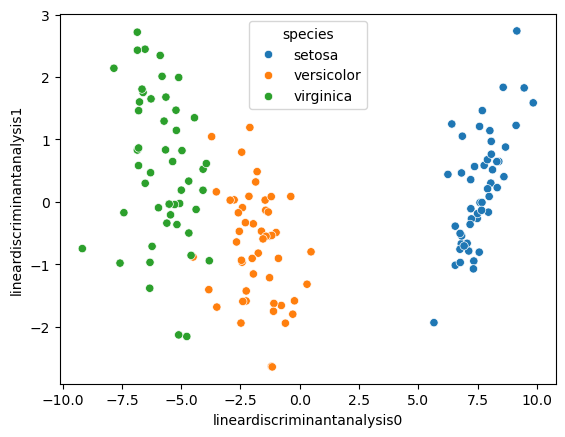

In [29]:
sns.scatterplot(x="lineardiscriminantanalysis0",y="lineardiscriminantanalysis1",hue="species",data=lda_data)
plt.show()

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

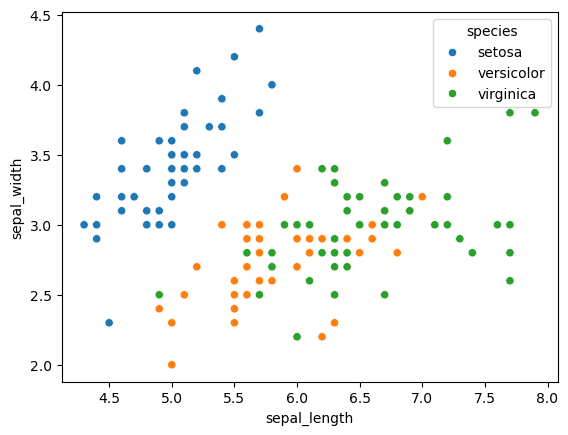

In [30]:
sns.scatterplot(x="sepal_length", y="sepal_width",data=iris,hue="species")

In [31]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [34]:
X, y = iris.drop("species",axis=1), iris["species"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3)

In [45]:
# scaler = StandardScaler().set_output(transform='pandas')
ks = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([("knn",knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["K","Score"])
df_scores.sort_values("Score",ascending=False)

,K,Score
9,10,0.977778
10,11,0.977778
11,12,0.977778
13,14,0.977778
14,15,0.977778
0,1,0.955556
1,2,0.955556
2,3,0.955556
3,4,0.955556
4,5,0.955556


In [32]:
lda_data.head()

,lineardiscriminantanalysis0,lineardiscriminantanalysis1,species
0,8.061800,0.300421,setosa
1,7.128688,-0.786660,setosa
2,7.489828,-0.265384,setosa
3,6.813201,-0.670631,setosa
4,8.132309,0.514463,setosa


In [49]:
X, y = lda_data.drop("species",axis=1), lda_data["species"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3)

In [50]:
scaler = StandardScaler().set_output(transform='pandas')
ks = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([("knn",knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["K","Score"])
df_scores.sort_values("Score",ascending=False)

,K,Score
0,1,1.000000
2,3,1.000000
3,4,1.000000
7,8,1.000000
8,9,1.000000
9,10,1.000000
10,11,1.000000
11,12,1.000000
12,13,1.000000
13,14,1.000000
